# Chapter 14: Files

Variables let us work with data while a program runs. **Files let us keep that data after the program finishes**, and read data created elsewhere.

We will read text, count and search its contents, then write our own files. Each example is followed by a small task for you to implement.

**Before starting:** put this notebook and the supplied `treasure.txt` in the same working folder. Run the examples in order. Keep `treasure.txt` as the source; save your results under the different filenames given below. The book includes a title page and licence text; our counts refer to the entire supplied file unless stated otherwise.

## 14.1 Strings: a quick refresher for working with files

In `for line in book:`, **`line` is a string**, usually including its ending newline (`\n`). A string is a sequence of characters: indexing and slicing work much like a list, but **strings are immutable**—you cannot assign to `text[0]`. String methods return new strings; save the result if you want to keep it.

- **Measure and select:** `len(text)`, `text[0]`, `text[-1]`, `text[start:stop]`.
- **Clean the ends:** `strip()` removes whitespace from both ends; `lstrip()` from the left (beginning); `rstrip()` from the right (end). Whitespace includes spaces, tabs and newlines.
- **Change the text:** `lower()`, `upper()`, `replace(old, new)`. Use `replace(old, "")` to remove every occurrence of a character or phrase.
- **Search:** `in` gives `True` or `False`; `find()` gives the first matching index, or `-1`; `count()` counts non-overlapping matches. These searches are case-sensitive.
- **Split into words:** `split()` returns a **list of strings**, separating at whitespace but keeping punctuation attached.

Run this cell and compare each result with the original sentence. Spaces and the newline count as characters too.

In [ ]:
text = "  The ship sailed north!\n"

print("Original:", text)
print("With quotes and visible escape characters:", repr(text))
print("Length:", len(text))
print("First character:", text[0])
print("Last character:", text[-1])
print("Slice [2:5]:", text[2:5])
print("Strip whitespace:", text.strip())
print("Remove trailing newline:", text.rstrip("\n"))
print("Remove ending punctuation:", text.strip().strip(".,!?"))
print("Lowercase:", text.lower())
print("Uppercase:", text.upper())
print("Replace north:", text.replace("north", "south"))
print("Remove spaces:", text.replace(" ", ""))
print("Contains ship:", "ship" in text)
print("Index of ship:", text.find("ship"))
print("Index of missing word:", text.find("boat"))
print("Count of i:", text.count("i"))
print("Words:", text.split())
print("Original still unchanged:", text)

### Exercise 1: Measure and select a label

Use `label = "Pump A: ready"`. Print its length, first character and last character. Then use a slice to print just `Pump A`. Spaces and punctuation count as characters.

In [ ]:
# Exercise 1: Measure and select a label


### Example: Clean the left end, right end, or both

With empty parentheses, these methods remove **whitespace**: spaces, tabs (`\t`) and newlines (`\n`). They leave spaces **between words** untouched.

- `lstrip()`: remove whitespace from the **beginning** (left).
- `rstrip()`: remove whitespace from the **end** (right).
- `strip()`: remove whitespace from **both ends**.

Here, `repr()` makes the remaining spaces, tab and newline visible. Each method returns a new string; the original stays unchanged.

In [ ]:
text = "  Pump A \t\n"

print("Original:", repr(text))
print("Left only:", repr(text.lstrip()))
print("Right only:", repr(text.rstrip()))
print("Both ends:", repr(text.strip()))
print("Original unchanged:", repr(text))


Give characters inside the parentheses to remove **only those characters** from the chosen ends. `strip("!?")` removes any run of `!` and `?` at either end—not an exact phrase, and not punctuation inside the string. `rstrip("\n")` removes trailing newlines while preserving spaces.

In [ ]:
label = "?!Pump-A!?"
print("Left punctuation:", label.lstrip("!?"))
print("Right punctuation:", label.rstrip("!?"))
print("Both ends:", label.strip("!?"))

line = "  Pump A  \n"
print("Only the newline removed:", repr(line.rstrip("\n")))
print("All trailing whitespace removed:", repr(line.rstrip()))


### Exercise 2: Clean a reading

Use `reading = "  24.6 C!\n"`.

1. Predict what `lstrip()`, `rstrip()` and `strip()` will leave behind. Print each result with `repr()` to check.
2. Save a version with whitespace removed from both ends, then remove the final `!` using `rstrip("!")`.
3. Print the cleaned reading and its length. Is the space between `24.6` and `C` still there?
4. Use `replace()` to remove that remaining space. Print the result and the original reading.

In [ ]:
# Exercise 2: Clean the ends


### Exercise 3: Update a message

Use `message = "Sensor-A: Sensor-A needs checking."`. Replace every `Sensor-A` with `Probe-B`, then remove the hyphens from the updated message. Print the result and the original message. Save each changed string in a variable.

In [ ]:
# Exercise 3: Update a message


### Exercise 4: Find a phrase regardless of capitals

Use `line = "Warning: LOW battery in sensor 3"`. Ask the user for a phrase, then print whether it occurs in the line. Convert **both** strings to lowercase before using `in`. Try `low battery`, `SENSOR` and a phrase that is absent. This checks for a substring, not necessarily a whole word.

In [ ]:
# Exercise 4: Find a phrase regardless of capitals


### Exercise 5: Split and clean words

Use `message = "Pump, valve! PUMP."`. Split it into words and print the word count. Use a loop to build a new list: lowercase each word and remove `.,!?` from its ends. Print the cleaned list. Then count how many cleaned words equal `pump` using a loop and `==`.

In [ ]:
# Exercise 5: Split and clean words


### Exercise 6: Count and locate a fault

Use `log = "Leak at valve A; leak at valve B."`. Make a lowercase copy. Print how many times `leak` occurs and the index where its first occurrence begins. Then search for `overheat` with `find()`. If the result is `-1`, print `Not found`; otherwise print the index.

In [ ]:
# Exercise 6: Count and locate a fault


## 14.2 Open a file, read it, then close it

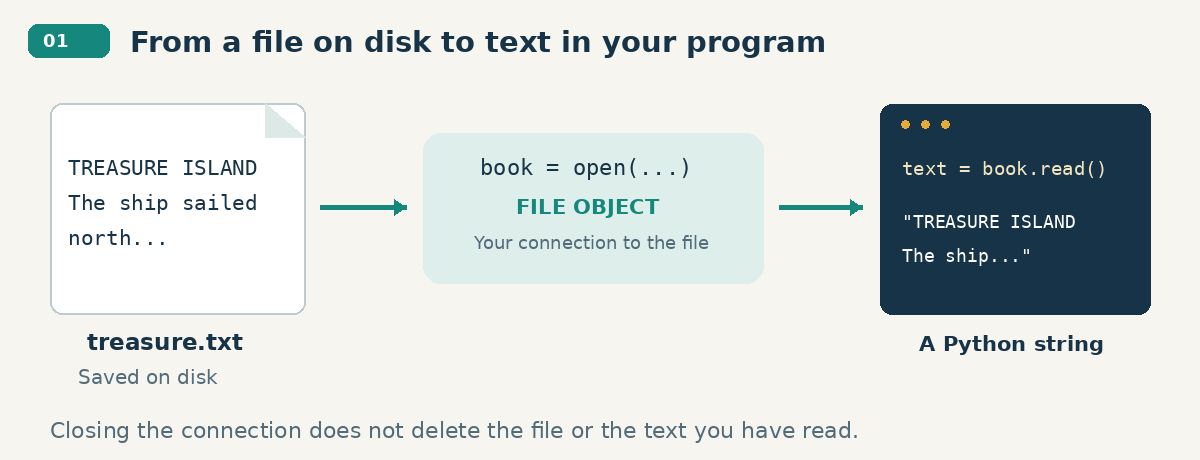

*A file object connects your program to the saved file; reading gives you text to work with.*

### Example: Read the first 100 characters

`open()` returns a **file object**: a connection to the file on disk. `book` names that object; `opening` holds the string we read. Mode `"r"` means read. `read(100)` returns the next 100 characters, or fewer at the end. `close()` releases the connection.

The file object keeps a **reading position**, often called an offset, like a bookmark. Reading moves it forwards. Another `book.read(100)` on the same open file reads the **next** block, not the first block again. Reopening the file starts at the beginning.

In [ ]:
book = open("treasure.txt", "r")
opening = book.read(100)
book.close()

print(opening)

### The same operation, reading the whole book

Leave the parentheses empty to read all **remaining** text. This example opens a fresh connection, so it reads from the start. Printing the whole book produces a long output; collapse that output afterwards.

In [ ]:
book = open("treasure.txt", "r")
whole_book = book.read()
book.close()

print(whole_book)

### Two reads on the same open file

The first call gets the first block; the second gets the following block. Keep the file open between calls so its bookmark can advance.

In [ ]:
book = open("treasure.txt", "r")
first_block = book.read(100)
second_block = book.read(100)
book.close()

print("First block:", first_block)
print("Next block:", second_block)

**Encoding, briefly:** a text file is stored using an encoding such as UTF-8. Python must decode it using the matching encoding. If we omit the encoding argument, Python chooses a default from its settings, which can depend on the computer. These examples use the default; if it is not UTF-8, use `open("treasure.txt", "r", encoding="utf-8")` for the supplied file.

### Where does Python look for the file?

`open("treasure.txt", "r")` looks in the **current working folder**. `Path.cwd()` shows that folder. It is often the folder containing your notebook or `.py` file, but an editor or launch command can choose a different folder. The file must be in the folder shown below for a filename alone to work:

In [ ]:
from pathlib import Path
print(Path.cwd())

### Give a folder path when the file is elsewhere

A **relative path** begins from the working folder, for example `"data/treasure.txt"`. An **absolute path** gives the full location.

On Windows, these two strings name the same example location:
```python
filename = "C:\\Documents\\treasure.txt"
filename = r"C:\Documents\treasure.txt"
```
In the first form, `\\` in Python code represents one backslash. In the second, the prefix `r` makes it a **raw string**, so use single backslashes. You can also use forward slashes: `"C:/Documents/treasure.txt"`.

For example, if the file actually exists there:
```python
book = open(r"C:\Documents\treasure.txt", "r")
opening = book.read(100)
book.close()
print(opening)
```
Change the folder to the file’s real location. The extension is `.txt`. A missing folder or mistyped filename produces `FileNotFoundError`.

### Exercise 7: Read two consecutive pieces

Open `treasure.txt` for reading. Read 40 characters into `first_piece`, then another 40 into `second_piece`. Close the file and print both pieces separately.

The second read continues from where the first stopped; it does not start again. Print `len(first_piece + second_piece)` to check that you read 80 characters in total.

In [ ]:
# Exercise 7: Read two consecutive pieces

## 14.3 Use with to close a file automatically

### Example: Read one line using next()

`with open(...) as book:` opens the file and closes it automatically when execution leaves the indented block. It is an alternative to writing `close()` yourself.

`next(book)` gets the next complete line and advances the reading position. The returned string normally includes its final newline character, `\n`. We will use `next()` for individual lines and a `for` loop for a whole file.

In [ ]:
with open("treasure.txt", "r") as book:
    first_line = next(book)

print(first_line, end="")

The variable `first_line` still holds the text after the file closes. `print(..., end="")` adds no extra newline because the line already includes one.

You may also encounter `book.readline()`: it reads the next line too. They differ at the end: `readline()` returns `""`, whereas `next(book)` raises `StopIteration`. We will keep to `next()` here; a `for` loop handles the end automatically.

### Exercise 8: Read the title-page opening

Using `with`, read the first **three physical lines** with three calls to `next(book)`. Print each without adding extra newlines, then print the length of each string.

The book has more than three lines, so these calls are safe. Its second line is blank: it contains only `"\n"`, which has length 1. Reading a blank line is not the same as reaching the end.

In [ ]:
# Exercise 8: Read the title-page opening

## 14.4 Loop through a file one line at a time

### Example: Display a short numbered preview

An open text file is an **iterator**: it supplies the next line each time the loop runs. Here the loop variable `line` holds one string. The counter labels physical lines, including blank lines. `break` stops this preview after five lines.

In [ ]:
with open("treasure.txt", "r") as book:
    line_number = 0
    for line in book:
        line_number += 1
        print(line_number, line.rstrip("\n"))
        if line_number == 5:
            break

`rstrip("\n")` removes trailing newline characters while preserving spaces. `strip()` removes whitespace from both ends, so it is useful for testing whether a line is blank.

A `for` loop asks the iterator for successive lines and stops automatically at the end. Reading this way avoids loading the entire book into a list. A list is **iterable** too, but its elements are already stored in memory.

### Example: Identify a blank line

A blank line may contain a newline, spaces or tabs. `line.strip()` removes all of those from the ends. If nothing remains, the result is the empty string `""`, so **`line.strip() == ""` identifies a blank line**.

In [ ]:
sample_lines = ["Hello\n", "\n", "   \n"]
for line in sample_lines:
    if line.strip() == "":
        print("Blank")
    else:
        print("Contains text")

### Exercise 9: Preview the first five non-blank lines

Loop through `treasure.txt` and print its first five **non-blank** lines. Do not count a line if `line.strip() == ""`. Stop after printing five.

This differs from the example: blank lines must not use up your five-line allowance. Keep the counter update inside the non-blank condition.

In [ ]:
# Exercise 9: Preview the first five non-blank lines

## 14.5 Count lines, characters and words

### Example: Count every line in a file

Open a fresh connection so reading begins at the start. Increase a counter once per line. Print the result after the file has closed.

In [ ]:
line_count = 0
with open("treasure.txt", "r") as book:
    for line in book:
        line_count += 1

print("Lines:", line_count)

### Exercise 10: Count blank and non-blank lines

Count blank lines and non-blank lines separately in `treasure.txt`. Start two counters at zero. For each line, test `line.strip() == ""`: increase the blank counter if true, otherwise increase the non-blank counter. Print both counts and their sum.

**Check:** their sum should match the total line count from the example.

In [ ]:
# Exercise 10: Count blank and non-blank lines

### Example: Count characters

Add the length of each string returned by the file. This includes spaces and newline characters.

In [ ]:
character_count = 0
with open("treasure.txt", "r") as book:
    for line in book:
        character_count += len(line)

print("Characters:", character_count)

### Exercise 11: Count words and find the longest line

Loop through the file. Count all whitespace-separated words using `split()`. Also find the greatest line length, excluding the trailing newline but keeping spaces. Print both results.

**Hint:** start a total at 0 and a longest length at 0. Update the longest only when a larger length is found; a blank file would give zero for both.

In [ ]:
# Exercise 11: Count words and find the longest line

## 14.6 Search the text

### Example: Find lines containing a search term

`in` tests whether a substring occurs in a string. Lowercase both sides for a case-insensitive search. This function prints at most three matching lines, together with their physical line numbers.

In [ ]:
def show_matches(filename, term):
    shown = 0
    line_number = 0
    with open(filename, "r") as source:
        for line in source:
            line_number += 1
            if term.lower() in line.lower():
                print(line_number, line.rstrip("\n"))
                shown += 1
                if shown == 3:
                    break

show_matches("treasure.txt", "island")

### Two different questions: matching lines or matching words?

The example above asks **“does this line contain this text?”** using `in`. Thus `"ship"` also matches `"ships"`, and a line is displayed once even if it contains several matches.

To ask **“how many times does this whole word occur?”**, split the line into words, clean their ends and compare each one using `==`. The next example shows that complete process on a short sentence before you apply it to a file.

### Example: Count the whole word ship in a sentence

Split into words, lowercase each word and strip the listed punctuation from its ends. Increase the count only when the cleaned word equals the target. Under this simple rule, `ships` and `ship-shaped` are different words from `ship`.

In [ ]:
sentence = "Ship, ship! ships."
target = "ship"
count = 0

for word in sentence.split():
    cleaned = word.lower().strip(".,;:!?\"'()[]“”‘’")
    if cleaned == target.lower():
        count += 1

print("Whole-word matches:", count)

### Exercise 12: Count a whole word in a file

Write `count_word(filename, target)` that returns the total whole-word matches in the file. Assume the target is one non-empty word with no punctuation.

1. Start the count before opening the file.
2. Loop through the lines. Inside that loop, use the sentence example’s split–clean–compare steps on the current line.
3. Return the count after all lines have been processed.

Call it for `"treasure"` and `"island"`. Count matching words, not matching lines; `"treasures"` must not count as `"treasure"`.

In [ ]:
# Exercise 12: Count a whole word

## 14.7 The reading position: a moving bookmark

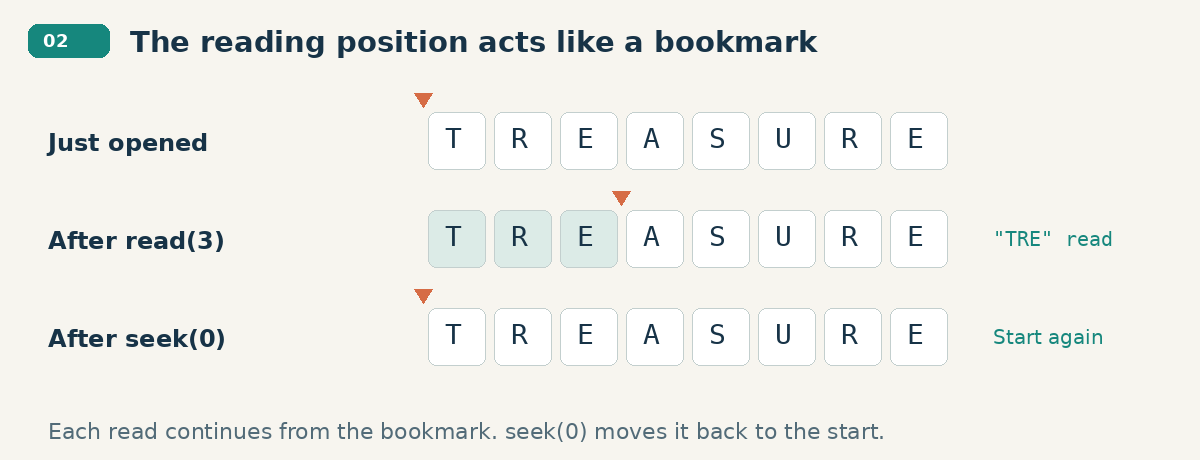

*Illustration using a short file containing `TREASURE`.*

### Example: Print the position after each read

`tell()` records the current reading position; `seek(0)` returns to the start. Print a labelled position before reading, after each block and after rewinding.

Text-file positions are bookmarks Python can reuse, not guaranteed character counts. Save a position and pass it back to `seek()` rather than calculating offsets yourself. We use `read()` in this example: do not mix `tell()` with file iteration using `next()` or `for`, which can disable position reporting.

In [ ]:
with open("treasure.txt", "r") as book:
    position_1 = book.tell()
    first = book.read(30)
    position_2 = book.tell()
    following = book.read(20)
    position_3 = book.tell()
    book.seek(0)
    position_4 = book.tell()
    first_again = book.read(30)
    position_5 = book.tell()

print("Position 1 — before reading:", position_1)
print("Position 2 — after 30 characters:", position_2)
print("Position 3 — after 20 more characters:", position_3)
print("Position 4 — after seek(0):", position_4)
print("Position 5 — after reading the first 30 again:", position_5)
print("Same opening:", first == first_again)

At the end, `read()` returns `""`. A second loop over an exhausted file finds nothing unless you rewind it or reopen it. The read and seek operations move the bookmark; `tell()` only reports it.

### Exercise 13: Save and revisit a reading position

Open the book and use `read(40)` to skip its first 40 characters. Save the position with `tell()`. Read the next 60 characters into `piece_a` and record another position. Seek back to the saved position and read 60 characters into `piece_b`.

Print clearly labelled positions before and after the 60-character read, then print whether the two pieces are equal. The comparison should be `True`. Keep these operations inside one `with` block and use `read()`, not `next()`.

In [ ]:
# Exercise 13: Save and revisit a reading position

## 14.8 Put file processing in a reusable function

### Example: Return the number of non-blank lines

The filename is a parameter, so the same function can process different files. Return the calculated result; let the caller choose how to display it.

In [ ]:
def count_nonblank_lines(filename):
    count = 0
    with open(filename, "r") as source:
        for line in source:
            if line.strip() != "":
                count += 1
    return count

print(count_nonblank_lines("treasure.txt"))

### Exercise 14: Return three file statistics

Write `file_stats(filename)` that returns **line count, word count and character count**, in that order. Process the file in one loop. Include blank lines in the line count and newlines in the character count; use `split()` for words.

Call it for `treasure.txt`, unpack the three results, and print clear labels. Compare with your earlier counts. An empty file should return `(0, 0, 0)`.

In [ ]:
# Exercise 14: Return three file statistics

## 14.9 Write text to a new file

### Example: Save a short note

Mode `"w"` creates a file or **replaces all its existing contents**. `write()` expects a string and does not add a newline automatically: include `\n` where needed. Leaving the `with` block closes the file and flushes buffered text; then reopen it to check the saved contents.

In [ ]:
with open("example_note.txt", "w") as destination:
    destination.write("Experiment 1\n")
    destination.write("Sensor connected\n")

with open("example_note.txt", "r") as source:
    print(source.read(), end="")

Use a new output filename, not `treasure.txt`. Re-running a write-mode cell replaces that output with a fresh version. The filename is a string; the file object is the object returned by `open()`.

### Exercise 15: Save an equipment label

Ask for an equipment name and a location. Write two labelled lines to `equipment_label.txt`, such as `Equipment: meter` and `Location: Lab 2`. End each line with a newline. Reopen the file and print its contents.

Use `"w"` so running the cell again replaces the previous label.

In [ ]:
# Exercise 15: Save an equipment label

## 14.10 Append without replacing existing text

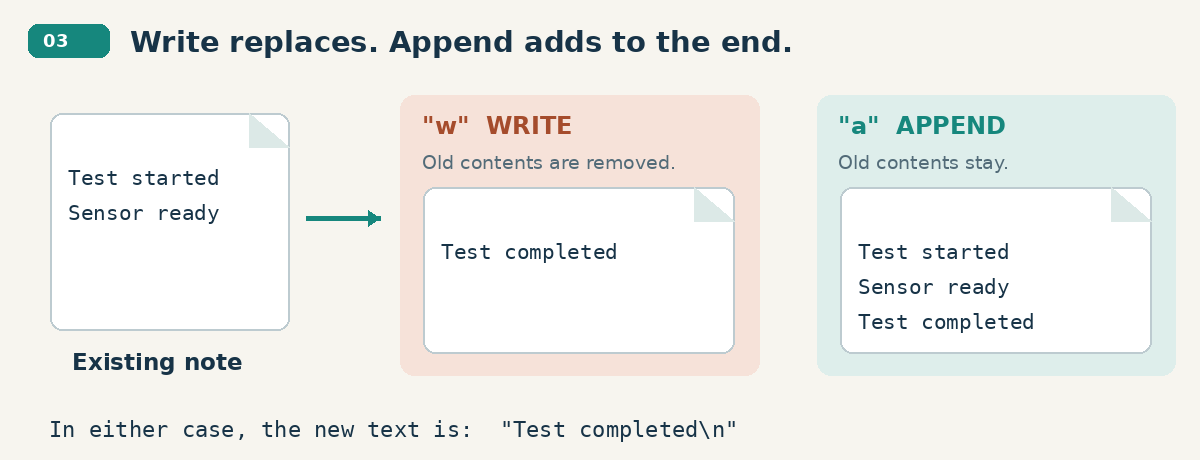

*Two alternatives, each starting from the same original note.*

### Example: Add another entry to the note

Mode `"a"` writes at the end, preserving existing contents; it creates the file if needed. Run the note example first. Each rerun of this append cell adds another entry.

In [ ]:
with open("example_note.txt", "a") as destination:
    destination.write("Test completed\n")

with open("example_note.txt", "r") as source:
    print(source.read(), end="")

### Exercise 16: Keep a short activity log

Write `append_entry(filename, message)` that appends the message followed by a newline. Call it twice to add two different entries to `activity_log.txt`, then read and print the file.

Run the cell again and observe that the old entries remain. Why would changing `"a"` to `"w"` inside the function lose earlier entries?

In [ ]:
# Exercise 16: Keep a short activity log

## 14.11 Write numbers as text

### Example: Save one number per line

A text file stores characters. Convert each number with `str()` before writing it, then add a newline. Keep the file open for the whole loop.

In [ ]:
values = [2, 4, 6, 8]
with open("example_numbers.txt", "w") as destination:
    for value in values:
        destination.write(str(value) + "\n")

with open("example_numbers.txt", "r") as source:
    print(source.read(), end="")

### Exercise 17: Save a table of squares

Write `save_squares(filename, n)` for a positive integer `n`. Save one line for each integer 1 through `n`, containing the number and its square separated by a space. Call it to create `squares.txt` for `n = 5`, then read the file back.

**Check:** the first line is `1 1`; the last is `5 25`. Convert both numbers to strings when building each line.

In [ ]:
# Exercise 17: Save a table of squares

## 14.12 Read numbers back and calculate with them

### Example: Calculate the total of saved numbers

Even a line that looks like `2` is read as text. Convert it with `float()` before arithmetic. Ignore blank lines. This example uses the file created in Section 14.11; each non-blank line must contain one valid number.

In [ ]:
total = 0
count = 0
with open("example_numbers.txt", "r") as source:
    for line in source:
        if line.strip() != "":
            total += float(line)
            count += 1

print("Count:", count)
print("Total:", total)

### Exercise 18: Find the average and count readings above a limit

Create `readings.txt` by writing `[18, 22, 19, 25, 21]`, one value per line. Write `reading_summary(filename, limit)` to return the average and the count strictly above the limit. Ignore blank lines; assume all other lines contain valid numbers. Return `None, 0` if there are no readings.

**Check:** limit 21 gives average 21.0 and count 2. Check the count before dividing.

In [ ]:
# Exercise 18: Find the average and count readings above a limit

## 14.13 Read from one file and write to another

### Example: Make a copy without blank lines

Open the source for reading and a different file for writing. The inner `with` closes the destination; the outer one closes the source. Write the original line to preserve its spacing and newline.

In [ ]:
with open("treasure.txt", "r") as source:
    with open("treasure_nonblank.txt", "w") as destination:
        for line in source:
            if line.strip() != "":
                destination.write(line)

### Exercise 19: Save all lines matching a search term

Ask for a non-empty search term. Copy every line of `treasure.txt` containing that substring, ignoring case, to `search_results.txt`. Preserve each matching line exactly as read. Print how many lines you copied.

Copy a line once even if the term occurs twice in it. Unlike the earlier preview, do not stop after three matches. No matches should produce an empty output file.

In [ ]:
# Exercise 19: Save all lines matching a search term

### Example: Make a changed line using replace()

`line.replace(old, new)` returns a **new string**, replacing every occurrence of `old`. It leaves the original string unchanged. Use `new = ""` to remove the matching text. `line.count(old)` counts the occurrences before replacement. Matching is case-sensitive.

In [ ]:
line = "Sensor ready; Sensor connected.\n"
new_line = line.replace("Sensor", "Probe")
shorter_line = line.replace("Sensor ", "")

print(line, end="")
print(new_line, end="")
print(shorter_line, end="")
print("Replacements:", line.count("Sensor"))

### Use the new line when writing a copy

Now apply the same string operation inside the file loop. This changes only the output file.

In [ ]:
with open("example_note.txt", "r") as source:
    with open("example_note_probe.txt", "w") as destination:
        for line in source:
            new_line = line.replace("Sensor", "Probe")
            destination.write(new_line)

### Exercise 20: Replace a phrase in a copy

Write `replace_in_file(source_name, output_name, old, new)` using different source and output filenames. Assume `old` is non-empty.

For each source line:
1. Add `line.count(old)` to a running replacement count.
2. Make `new_line = line.replace(old, new)`.
3. Write `new_line` to the output file.

Return the total replacement count. Test with `example_note.txt`, replacing `Sensor` with `Probe` into `revised_note.txt`. Then read back the new file. Matching is case-sensitive and phrases must lie within one line. The original must remain unchanged.

In [ ]:
# Exercise 20: Replace a phrase in a copy

## 14.14 Read lines into a list when you need their order

### Example: Turn the remaining file lines into a list

A file supplies successive lines, so **`list(source)` collects its remaining lines into a list**. Each line keeps its newline character. This loads the remaining text into memory, which is useful for slicing or reordering a short file.

`source.readlines()` is an alternative that produces the same list from the same reading position. Both consume the remaining lines; calling one immediately after the other would give an empty list the second time.

In [ ]:
with open("example_note.txt", "r") as source:
    lines = list(source)

print("Number of lines:", len(lines))
print("Last line:", lines[-1].rstrip("\n"))

with open("example_note.txt", "r") as source:
    alternative = source.readlines()

print("Same list:", lines == alternative)

### Exercise 21: Reverse the order of saved readings

Use `example_numbers.txt` from Section 14.11. Read its lines into a list and write them in reverse order to `numbers_reversed.txt`. Reverse the **line order**, not the characters within each line.

**Check:** the new file contains 8, 6, 4, 2 on separate lines; the original stays unchanged. Use `lines[::-1]`. Every line in this source already ends with a newline.

In [ ]:
# Exercise 21: Reverse the order of saved readings

## 14.15 Check a filename before reading it

### Example: Check whether a file is available

`Path(filename).is_file()` checks whether the path currently names a regular file. If it exists, read the first line. Here `next(source, "")` supplies an empty string as a default if the file is empty, instead of raising `StopIteration`. Other access errors are a later topic.

In [ ]:
from pathlib import Path

filename = "treasure.txt"
if Path(filename).is_file():
    with open(filename, "r") as source:
        print(next(source, ""), end="")
else:
    print("File not found:", filename)

### Exercise 22: Preview a file chosen by the user

Write `preview_file(filename, count)` for a non-negative integer count. If the file is absent, print `File not found`. Otherwise print up to `count` physical lines without extra newlines, stopping naturally if the file is shorter. For count 0, print no lines.

Ask for a filename and a count, then call your function. Test an existing file, a missing file, count 0, and a count larger than the file’s length. Use a direct file loop and a counter rather than unguarded `next()` calls.

In [ ]:
# Exercise 22: Preview a file chosen by the user

## Homework: ten short file-handling tasks

Write each solution in its empty cell. Use `with` for file access and keep `treasure.txt` unchanged. Each task stands alone: create the small source files specified in that task. Use functions where requested, then call them to test your code. Assume numeric data is valid except for the blank lines explicitly mentioned.

### Homework 1: Save a short experiment record

Ask for an experiment name and three notes. Write them to `experiment_record.txt`, one entry per line. Reopen the file and print its contents with line numbers starting at 1. Re-running the cell should replace the old record.

### Homework 2: Compare blank and non-blank lines

Write `blank_summary(filename)` returning the blank-line count and non-blank-line count. Test on `treasure.txt`. Also create `blank_test.txt` containing exactly `"alpha\n\n   \nbeta\n"` using `write()`, interpreting the escapes as newlines. **Check:** two blank and two non-blank lines.

### Homework 3: Copy even-numbered lines

Copy physical lines 2, 4, 6, … of `treasure.txt` into `even_lines.txt`. Preserve blank lines when they fall at an even position. Print the copied-line count. **Check:** it is the original physical line count divided by 2 using integer division.

### Homework 4: Find the first matching line

Write `first_match(filename, term)` that returns the first matching physical line number and its text, using a case-insensitive substring search. Assume a non-empty term. Return `None, ""` if nothing matches. Test with `Treasure` and a term you expect to be absent.

### Homework 5: Build a word-count report

Write `word_report(source_name, output_name)` that saves the total word count and the number of non-blank lines to a two-line labelled report. Use whitespace-separated words. Call it for `treasure.txt`, saving to `book_report.txt`, then read and print the report.

### Homework 6: Save a Fibonacci sequence

Write `save_fibonacci(filename, count)` for a non-negative integer count. Save exactly that many Fibonacci terms beginning 0, 1, one per line. **Check:** count 7 gives 0, 1, 1, 2, 3, 5, 8. Count 0 gives an empty file; count 1 writes only 0. Test using `fibonacci.txt`.

### Homework 7: Read back numbers and select some

Create `temperatures.txt` containing `[16, 22, 18, 25, 20]`, one per line. Write `save_above(source_name, output_name, limit)` that saves only readings strictly above the limit and returns their count. Ignore blank lines. **Check:** limit 20 saves 22 and 25 to `high_temperatures.txt`, count 2.

### Homework 8: Read two values from each line

Create `pairs.txt` containing the lines `2 5`, `3 7`, and `4 1`. Write `product_total(filename)` that splits each non-blank line, converts its two values to numbers, and returns the sum of their products. **Check:** 10 + 21 + 4 = 35. Assume exactly two valid numbers on each non-blank line.

### Homework 9: Keep a log across function calls

Write `log_result(filename, test_name, result)` that appends one line in the form `test_name: result`. Use it three times with different test names in `test_log.txt`, then print the file. Call it once more and verify that the earlier entries remain. Always end an entry with a newline.

### Homework 10: Reverse short notes safely

Create `notes.txt` containing exactly `"connect\nmeasure\nsave"`, with no newline after the final word. Read its lines and write them in reverse order to `reversed_notes.txt`, ensuring that every output line ends with exactly one newline. **Hint:** remove the old trailing newline with `rstrip("\n")`, then add `"\n"`. **Check:** save, measure, connect appear on separate lines.